In [4]:
import numpy as np
import time
import torch
import matplotlib.pyplot as plt
plt.rc('text', usetex=False)
import multiprocessing as mp
from typing import Union


from abc import ABC
from epde.preprocessing.cheb import process_point_cheb

from epde.preprocessing.deriv_calculators import Heatmap, AbstractDeriv, AdaptiveFiniteDeriv, PolynomialDeriv, SpectralDeriv, TotalVariation

Mean Squared Error (MSE) for noise level 0:
  u_xx: 4.649569906394916e-25
  u_tt: 3.971690093210271e-25
Mean Squared Error (MSE) for noise level 0.005:
  u_xx: 4.462314081615636e-25
  u_tt: 4.420713371388575e-25
Mean Squared Error (MSE) for noise level 0.01:
  u_xx: 4.499908001872474e-25
  u_tt: 4.9763145775510095e-25


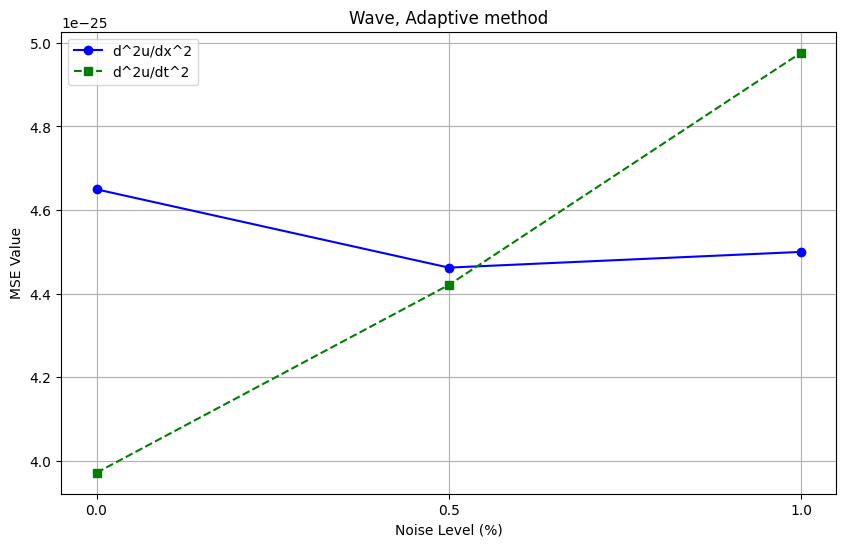

In [5]:
#ошибка дифференцирования между аналитической производной и численной для каждого слагаемого
import matplotlib as mpl
mpl.rc('text', usetex=False)
def calculate_mse(matrix1, matrix2):
    return np.mean((matrix1 - matrix2) ** 2)

noise_levels = [0, 0.005, 0.01]
noise_levels_percent = [0, 0.5, 1]

mse_values_u_xx = []
mse_values_u_tt = []

for noise in noise_levels:
    u_xx = np.load(f'Wave_Gradient_xx_noise{noise}.npy')
    u_tt = np.load(f'Wave_Gradient_tt_noise{noise}.npy')
    
    gradient_xx = np.load(f'Wave_Adaptive_xx_noise{noise}.npy')
    gradient_tt = np.load(f'Wave_Adaptive_tt_noise{noise}.npy')

    u_xx = u_xx[5:27, 5:27]
    u_tt = u_tt[5:27, 5:27]
    

    gradient_xx = gradient_xx[5:27, 5:27]
    gradient_tt = gradient_tt[5:27, 5:27]

    # Вычисление MSE для каждого случая
    mse_u_xx = calculate_mse(u_xx, gradient_xx)
    mse_u_tt = calculate_mse(u_tt, gradient_tt)
    
    mse_values_u_xx.append(mse_u_xx)
    mse_values_u_tt.append(mse_u_tt)
    
    print(f'Mean Squared Error (MSE) for noise level {noise}:')
    print(f'  u_xx: {mse_u_xx}')
    print(f'  u_tt: {mse_u_tt}')

plt.figure(figsize=(10, 6))
plt.plot(noise_levels_percent, mse_values_u_xx, marker='o', linestyle='-', color='b', label='d^2u/dx^2')
plt.plot(noise_levels_percent, mse_values_u_tt, marker='s', linestyle='--', color='g', label='d^2u/dt^2')

plt.title('Wave, Adaptive method')
plt.xlabel('Noise Level (%)')
plt.ylabel('MSE Value')
plt.xticks(noise_levels_percent)
plt.legend()
plt.grid()
plt.savefig('Wave_Adaptive_error.pdf', format='pdf')
plt.show()


Mean Squared Error (MSE) for noise level 0:
  u_xx: 0.0020393736016886795
  u_tt: 3.1118371791235185e-08
Mean Squared Error (MSE) for noise level 0.005:
  u_xx: 296.3631132961533
  u_tt: 297.0768425486123
Mean Squared Error (MSE) for noise level 0.01:
  u_xx: 1098.5014992498823
  u_tt: 1260.9453755141492


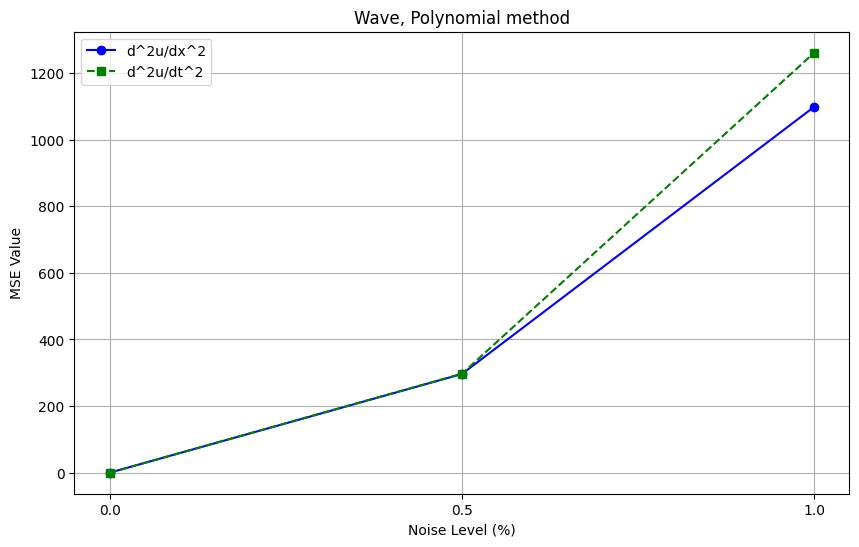

In [5]:
#ошибка дифференцирования между аналитической производной и численной для каждого слагаемого
import matplotlib as mpl
mpl.rc('text', usetex=False)
def calculate_mse(matrix1, matrix2):
    return np.mean((matrix1 - matrix2) ** 2)

noise_levels = [0, 0.005, 0.01]
noise_levels_percent = [0, 0.5, 1]

mse_values_u_xx = []
mse_values_u_tt = []

for noise in noise_levels:
    u_xx = np.load(f'Wave_Gradient_xx_noise{noise}.npy')
    u_tt = np.load(f'Wave_Gradient_tt_noise{noise}.npy')
    
    gradient_xx = np.load(f'Wave_Polynomial_xx_noise{noise}.npy')
    gradient_tt = np.load(f'Wave_Polynomial_tt_noise{noise}.npy')

    u_xx = u_xx[5:27, 5:27]
    u_tt = u_tt[5:27, 5:27]
    

    gradient_xx = gradient_xx[5:27, 5:27]
    gradient_tt = gradient_tt[5:27, 5:27]
        
    # Вычисление MSE для каждого случая
    mse_u_xx = calculate_mse(u_xx, gradient_xx)
    mse_u_tt = calculate_mse(u_tt, gradient_tt)
    
    mse_values_u_xx.append(mse_u_xx)
    mse_values_u_tt.append(mse_u_tt)
    
    print(f'Mean Squared Error (MSE) for noise level {noise}:')
    print(f'  u_xx: {mse_u_xx}')
    print(f'  u_tt: {mse_u_tt}')

plt.figure(figsize=(10, 6))
plt.plot(noise_levels_percent, mse_values_u_xx, marker='o', linestyle='-', color='b', label='d^2u/dx^2')
plt.plot(noise_levels_percent, mse_values_u_tt, marker='s', linestyle='--', color='g', label='d^2u/dt^2')

plt.title('Wave, Polynomial method')
plt.xlabel('Noise Level (%)')
plt.ylabel('MSE Value')
plt.xticks(noise_levels_percent)
plt.legend()
plt.grid()
plt.savefig('Wave_Polynomial_error.pdf', format='pdf')
plt.show()


Mean Squared Error (MSE) for noise level 0:
  u_xx: 3975.577916869921
  u_tt: 3283.7298475041125
Mean Squared Error (MSE) for noise level 0.005:
  u_xx: 5250.7933606751885
  u_tt: 4299.972279975277
Mean Squared Error (MSE) for noise level 0.01:
  u_xx: 8281.937342588815
  u_tt: 9248.8831023158


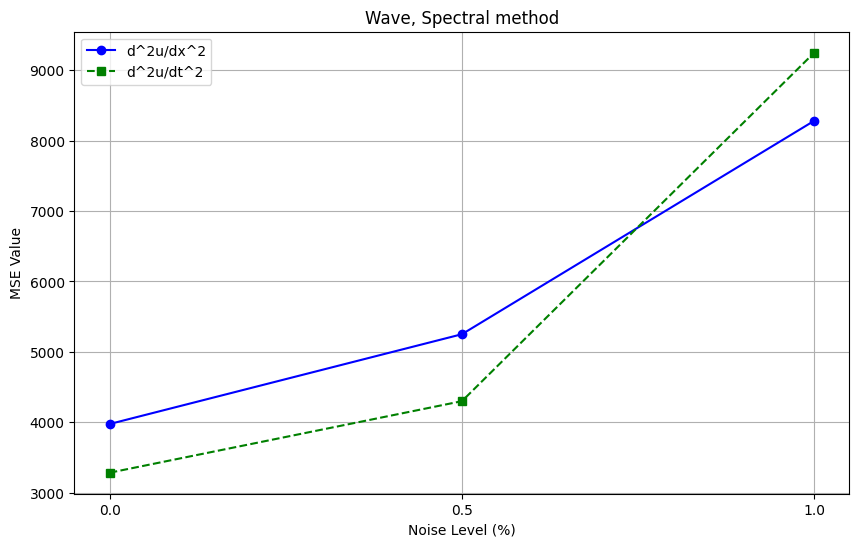

In [7]:
#ошибка дифференцирования между аналитической производной и численной для каждого слагаемого
import matplotlib as mpl
mpl.rc('text', usetex=False)
def calculate_mse(matrix1, matrix2):
    return np.mean((matrix1 - matrix2) ** 2)

noise_levels = [0, 0.005, 0.01]
noise_levels_percent = [0, 0.5, 1]

mse_values_u_xx = []
mse_values_u_tt = []

for noise in noise_levels:
    u_xx = np.load(f'Wave_Gradient_xx_noise{noise}.npy')
    u_tt = np.load(f'Wave_Gradient_tt_noise{noise}.npy')
    
    gradient_xx = np.load(f'Wave_Spectral_xx_noise{noise}.npy')
    gradient_tt = np.load(f'Wave_Spectral_tt_noise{noise}.npy')

    u_xx = u_xx[5:27, 5:27]
    u_tt = u_tt[5:27, 5:27]
    

    gradient_xx = gradient_xx[5:27, 5:27]
    gradient_tt = gradient_tt[5:27, 5:27]
        
    # Вычисление MSE для каждого случая
    mse_u_xx = calculate_mse(u_xx, gradient_xx)
    mse_u_tt = calculate_mse(u_tt, gradient_tt)
    
    mse_values_u_xx.append(mse_u_xx)
    mse_values_u_tt.append(mse_u_tt)
    
    print(f'Mean Squared Error (MSE) for noise level {noise}:')
    print(f'  u_xx: {mse_u_xx}')
    print(f'  u_tt: {mse_u_tt}')

plt.figure(figsize=(10, 6))
plt.plot(noise_levels_percent, mse_values_u_xx, marker='o', linestyle='-', color='b', label='d^2u/dx^2')
plt.plot(noise_levels_percent, mse_values_u_tt, marker='s', linestyle='--', color='g', label='d^2u/dt^2')

plt.title('Wave, Spectral method')
plt.xlabel('Noise Level (%)')
plt.ylabel('MSE Value')
plt.xticks(noise_levels_percent)
plt.legend()
plt.grid()
plt.savefig('Wave_Spectral_error.pdf', format='pdf')
plt.show()


Mean Squared Error (MSE) for noise level 0:
  u_xx: 15075.220812039654
  u_tt: 59.17233968469567
Mean Squared Error (MSE) for noise level 0.005:
  u_xx: 16376.164570318193
  u_tt: 1341.7406638547063
Mean Squared Error (MSE) for noise level 0.01:
  u_xx: 19982.604428109065
  u_tt: 6108.152958491463


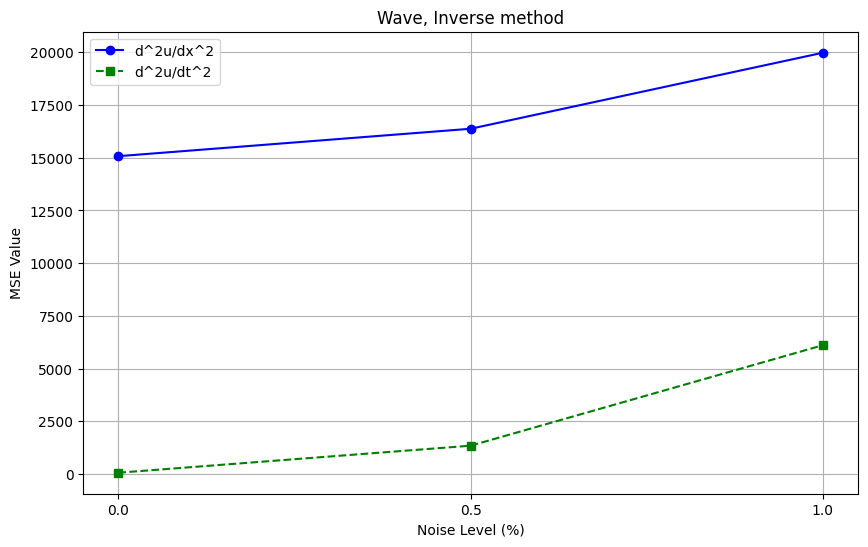

In [11]:
#ошибка дифференцирования между аналитической производной и численной для каждого слагаемого
import matplotlib as mpl
mpl.rc('text', usetex=False)
def calculate_mse(matrix1, matrix2):
    return np.mean((matrix1 - matrix2) ** 2)

noise_levels = [0, 0.005, 0.01]
noise_levels_percent = [0, 0.5, 1]

mse_values_u_xx = []
mse_values_u_tt = []

for noise in noise_levels:
    u_xx = np.load(f'Wave_Gradient_xx_noise{noise}.npy')
    u_tt = np.load(f'Wave_Gradient_tt_noise{noise}.npy')
    
    gradient_xx = np.load(f'Wave_Inverse_xx_noise{noise}.npy')
    gradient_tt = np.load(f'Wave_Inverse_tt_noise{noise}.npy')

    u_xx = u_xx[5:27, 5:27]
    u_tt = u_tt[5:27, 5:27]
    

    gradient_xx = gradient_xx[5:27, 5:27]
    gradient_tt = gradient_tt[5:27, 5:27]
       
    # Вычисление MSE для каждого случая
    mse_u_xx = calculate_mse(u_xx, gradient_xx)
    mse_u_tt = calculate_mse(u_tt, gradient_tt)
    
    mse_values_u_xx.append(mse_u_xx)
    mse_values_u_tt.append(mse_u_tt)
    
    print(f'Mean Squared Error (MSE) for noise level {noise}:')
    print(f'  u_xx: {mse_u_xx}')
    print(f'  u_tt: {mse_u_tt}')

plt.figure(figsize=(10, 6))
plt.plot(noise_levels_percent, mse_values_u_xx, marker='o', linestyle='-', color='b', label='d^2u/dx^2')
plt.plot(noise_levels_percent, mse_values_u_tt, marker='s', linestyle='--', color='g', label='d^2u/dt^2')

plt.title('Wave, Inverse method')
plt.xlabel('Noise Level (%)')
plt.ylabel('MSE Value')
plt.xticks(noise_levels_percent)
plt.legend()
plt.grid()
plt.savefig('Wave_Inverse_error.pdf', format='pdf')
plt.show()


Mean Squared Error (MSE) for noise level 0:
  u_xx: 15318.409977869442
  u_tt: 68.11209453863745
Mean Squared Error (MSE) for noise level 0.005:
  u_xx: 16622.291501772546
  u_tt: 1353.3664348651241
Mean Squared Error (MSE) for noise level 0.01:
  u_xx: 20238.94302459033
  u_tt: 6130.283646678662


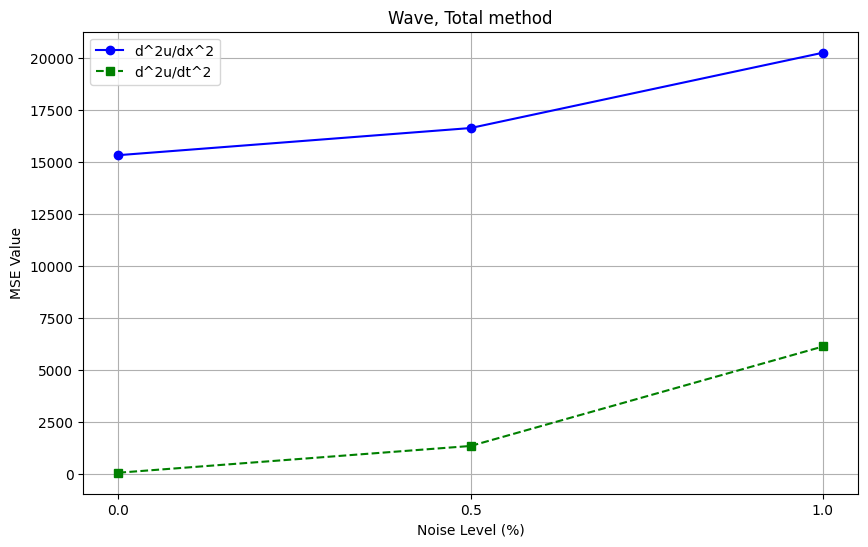

In [13]:
#ошибка дифференцирования между аналитической производной и численной для каждого слагаемого
import matplotlib as mpl
mpl.rc('text', usetex=False)
def calculate_mse(matrix1, matrix2):
    return np.mean((matrix1 - matrix2) ** 2)

noise_levels = [0, 0.005, 0.01]
noise_levels_percent = [0, 0.5, 1]

mse_values_u_xx = []
mse_values_u_tt = []

for noise in noise_levels:
    u_xx = np.load(f'Wave_Gradient_xx_noise{noise}.npy')
    u_tt = np.load(f'Wave_Gradient_tt_noise{noise}.npy')
    
    gradient_xx = np.load(f'Wave_Total_xx_noise{noise}.npy')
    gradient_tt = np.load(f'Wave_Total_tt_noise{noise}.npy')

    u_xx = u_xx[5:27, 5:27]
    u_tt = u_tt[5:27, 5:27]
    

    gradient_xx = gradient_xx[5:27, 5:27]
    gradient_tt = gradient_tt[5:27, 5:27]
        
    # Вычисление MSE для каждого случая
    mse_u_xx = calculate_mse(u_xx, gradient_xx)
    mse_u_tt = calculate_mse(u_tt, gradient_tt)
    
    mse_values_u_xx.append(mse_u_xx)
    mse_values_u_tt.append(mse_u_tt)
    
    print(f'Mean Squared Error (MSE) for noise level {noise}:')
    print(f'  u_xx: {mse_u_xx}')
    print(f'  u_tt: {mse_u_tt}')

plt.figure(figsize=(10, 6))
plt.plot(noise_levels_percent, mse_values_u_xx, marker='o', linestyle='-', color='b', label='d^2u/dx^2')
plt.plot(noise_levels_percent, mse_values_u_tt, marker='s', linestyle='--', color='g', label='d^2u/dt^2')

plt.title('Wave, Total method')
plt.xlabel('Noise Level (%)')
plt.ylabel('MSE Value')
plt.xticks(noise_levels_percent)
plt.legend()
plt.grid()
plt.savefig('Wave_Total_error.pdf', format='pdf')
plt.show()
